# M14.4 — Estructura de correlación de los residuos (M14.1)

**Pre-registro:** `docs/experiments/M14_4_residual_correlation.md` (11-11-2026). Este notebook lo aplica literalmente.

- **Modelo:** M14.1 (`M14_1_4a_G3T_hetero_s123_final.pt`), μ y σ estandarizadas. Solo se leen predicciones ya guardadas de cal y val de G3T (`preds_cal_G3T`, `preds_val_G3T`). No se cargan modelos, no se lee X y no se usa test.
- **z = (y − μ)/σ** por etiqueta, en unidades estandarizadas. Orden de etiquetas: [chirp_mass, total_mass, chi_eff].
- **Grupos desde X:** deciles de τ30 predicha = `tau_newtonian(μ_chirp)` (unidades físicas, la misma función que M14.1 y M14.3), con cortes en cal. Agregados D1–D3, D4–D7 y D8–D10.
- **G:** Σ(x) = D R D con R = correlación de z en cal. **P:** Σ(x) = D R_g(x) D con R_g = correlación de z en cal dentro del decil de τ30 predicha de la fila. D = diag(σ(x)).
- **Score:** s = (y − μ)ᵀ Σ(x)⁻¹ (y − μ) = zᵀ R⁻¹ z, en 3D (tres etiquetas) y 2D (chirp, total). Radio = estadístico k-ésimo de s en cal, k = ⌈(n_cal + 1)·0,9⌉. Volumen en unidades físicas: c_d sqrt(det Σ_fís(x)) r^(d/2), con c_d el volumen de la bola unidad (se cancela en Δ).
- **Decisión en val** (validez, ganancia Δ con IC por bootstrap emparejado, decisión). El bootstrap remuestrea filas de val con radios y R fijos: no incluye el ruido de cal.
- **Intervalos v2 de M14.3:** se reconstruyen sin reajustar v1. Se carga el bundle v1 del run ejecutado de M14.3 (sha256 comprobado frente a su JSON), v2 se reajusta en cal con `fit_v2` de M14.3 (determinista) y se aplica en val. Se exige reproducir los offsets de v2 y la tabla de cobertura y anchura por tercil de SNR del resumen de M14.3.

| Origen | Celda | Qué se reutiliza |
|---|---|---|
| M13.7 | 11 | `read_hdf5_dataset_preserve_order` |
| M14.3 | 12 | `fit_v2` |
| M14.3 | 14 | `apply_v2`, `per_row` |
| M14.3 | 34 | `to_json`, `records`, `input_entry` |

La aplicación de v1 en val repite las llamadas de la celda 8 de M13.7 (`apply_mondrian` sobre una copia del modelo de dificultad y `evaluate_mondrian`) sin escribir sus CSV.

## 1. Parámetros y CONFIG

In [1]:
TAG = "M14_1_4a_G3T_hetero_s123"
EXPECTED_CHECKPOINT_NAME = f"{TAG}_final.pt"
G3T_MARK = "m13_13_g3t"
MEMMAP_NAMES = {"cal": "fp16_memmap_heldout", "val": "fp16_memmap"}   # only row_ids_<split>.npy is read, never X

# Inputs (relative to <data_root>/results/): M14.1 inference on G3T. Test is not used in M14.4.
PRED_REL = {"cal": f"M13_3/{TAG}/preds_cal_G3T/cal_predictions_embeddings.npz",
            "val": f"M13_3/{TAG}/preds_val_G3T/val_predictions_embeddings.npz"}
TRAIN_CFG_REL = "configs/experiments/m14/train_m14_1_4aG3T_hetero_s123.json"  # dataset block: split, scaler
G3_CFG_REL = "configs/experiments/m13/train_m13_4a_G3aug_s123.json"           # G3 HDF5: y and SNR, as in M14.1
SNR_KEY = "target_network_snr"

# Gates.
N_EXPECTED = {"cal": 30_000, "val": 40_000}
Y_RTOL, Y_ATOL = 1e-5, 1e-6
# Val RMSE of mu (physical units) as recorded for M14.1 and M14.3; checked to the written precision.
RMSE_VAL_EXPECTED = {"chirp_mass": (5.268, 3), "total_mass": (8.799, 3), "chi_eff": (0.1678, 4)}

# Executed M14.3 run (source of the v1 bundle and of the reproduction targets for v2).
M14_3_RUN = "run_20261111T152944Z"
M14_3_SUMMARY_NAME = "M14_3_summary_20261111T153122Z.json"
BUNDLE_NAME = "mondrian_m13_7_4b_calibrators_cal_only.pkl"   # fixed file name of M13.7 cell 6
PRIMARY_POLICY = "conservative"
REPRO_ATOL = 1e-12

# Pre-registered design.
LEVEL = 0.90
N_TAU_DECILES = 10
TAU_GROUPS = {"D1-D3": (0, 1, 2), "D4-D7": (3, 4, 5, 6), "D8-D10": (7, 8, 9)}   # decile indices 0..9
DIMS = {"3D": (0, 1, 2), "2D": (0, 1)}                                        # 2D = (chirp, total)
VALID_BAND_LEVEL = 0.95
N_BOOT, SEED_BOOT, BOOT_BLOCK = 1000, 144001, 50   # BOOT_BLOCK: replicates per vectorised block (memory only)
CI_LEVEL = 0.95
DECISION_DELTA_MAX_PCT = -10.0                     # upper CI of Delta in 3D must be <= this

# Descriptive correlations: the doc fixes no seed or B for these CIs (not pre-registered choices).
N_BOOT_DESC, SEED_DESC, DESC_BLOCK = 1000, 144002, 50

CONFIG = dict(
    methods=dict(G=dict(name="G (R global)", color="0.35", ls="--"),
                 P=dict(name="P (R por decil de τ30 predicha)", color="#2a6fb0", ls="-")),
    v2=dict(name="rectángulo v2 (M14.3)", color="#c4512b"),
    labels={"chirp_mass": "chirp mass", "total_mass": "total mass", "chi_eff": "χ_eff"},
    units={"chirp_mass": "M☉", "total_mass": "M☉", "chi_eff": "adim."},
    val_color="#2a6fb0", cal_color="0.35", truth_color="k",
    # Representative val rows for figure (b): row nearest to this quantile of the variable.
    # "tau": predicted tau30; "sigma2d": log sigma_chirp + log sigma_total.
    representative=dict(tau_short=("tau", 0.05), tau_long=("tau", 0.95),
                        sigma_low=("sigma2d", 0.05), sigma_high=("sigma2d", 0.95)),
    fig_names=dict(a="M14_4_val_z_correlation_by_tau_pred_decile", b="M14_4_val_ellipses_2d_examples"),
)

## 2. Imports, rutas y código reutilizado

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from copy import copy
from dataclasses import replace
import sys, ast, json, pickle, hashlib
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.conformal.pipeline import apply_mondrian, evaluate_mondrian, MondrianPrediction
from src.conformal.binning import BinGrouper                     # used by the reused fit_v2
from src.conformal.calibration import ConformalIntervalCalibrator  # used by the reused fit_v2
from scripts.m13.m13_1_diagnostics import tau_newtonian   # same tau30 as M14.1, M13.13 and M14.3

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]

train_cfg = read_json(PROJECT_ROOT / TRAIN_CFG_REL)
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID_G3T = train_cfg["dataset"]["dataset_id"]
require(DATASET_ID_G3T == f"M13_G3_band1024_w16_500k/{G3T_MARK}", "Unexpected M14.1 dataset")
SPLIT_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                        file_name=train_cfg["dataset"]["split_file"])
LABEL_STATS_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3T,
                                              file_name=train_cfg["dataset"]["label_stats_file"])
g3_ds = read_json(PROJECT_ROOT / G3_CFG_REL)["dataset"]
DATASET_ID_G3 = g3_ds["dataset_id"]
require(G3T_MARK not in DATASET_ID_G3 and DATASET_ID_G3T == f"{DATASET_ID_G3}/{G3T_MARK}", "G3 / G3T dataset ids")
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID_G3, file_name=g3_ds["dataset_file"])
G3T_DIR = DATA_ROOT / "processed" / DATASET_ID_G3T
MEMMAP_DIRS = {s: G3T_DIR / name for s, name in MEMMAP_NAMES.items()}

RESULTS = DATA_ROOT / "results"
M13_DIR = RESULTS / "M13_3"
PRED_PATHS = {s: RESULTS / rel for s, rel in PRED_REL.items()}
M14_3_ROOT = M13_DIR / "M14_3"
M14_3_BUNDLE = M14_3_ROOT / M14_3_RUN / BUNDLE_NAME
M14_3_SUMMARY = M14_3_ROOT / M14_3_SUMMARY_NAME
M13_7_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb"
M14_3_NOTEBOOK = PROJECT_ROOT / "notebooks/m14/M14_3_mondrian_v2.ipynb"

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT_ROOT = M13_DIR / "M14_4"
FIG_DIR = OUT_ROOT / "figures"

inputs_to_check = [("pred cal", PRED_PATHS["cal"]), ("pred val", PRED_PATHS["val"]),
    ("row_ids cal", MEMMAP_DIRS["cal"] / "row_ids_cal.npy"), ("row_ids val", MEMMAP_DIRS["val"] / "row_ids_val.npy"),
    ("G3 HDF5 (y, SNR)", G3_H5), ("split", SPLIT_PATH), ("label stats (train only)", LABEL_STATS_PATH),
    ("M14.3 v1 bundle", M14_3_BUNDLE), ("M14.3 summary", M14_3_SUMMARY),
    ("M13.7 notebook", M13_7_NOTEBOOK), ("M14.3 notebook", M14_3_NOTEBOOK)]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")
print("Run stamp:", RUN_STAMP)

# Reuse of closed notebooks without copying them (same mechanism as M14.3, cell 4).
NOTEBOOK_CELLS = {"M13_7": read_json(M13_7_NOTEBOOK)["cells"], "M14_3": read_json(M14_3_NOTEBOOK)["cells"]}
reused_sources = {}

def reuse_cell(source, cell_index, names):
    """Define here only the functions `names` of a code cell of a closed notebook."""
    cell = NOTEBOOK_CELLS[source][cell_index]
    require(cell["cell_type"] == "code", f"{source} cell {cell_index} is not code")
    text = "".join(cell["source"])
    tree = ast.parse(text)
    tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names]
    require({n.name for n in tree.body} == set(names), f"{source} cell {cell_index} does not define {names}")
    reused_sources[f"{source}/cell_{cell_index}"] = dict(names=names, sha256=hashlib.sha256(text.encode()).hexdigest())
    exec(compile(tree, f"{source}_cell_{cell_index}", "exec"), globals())

reuse_cell("M13_7", 11, ["read_hdf5_dataset_preserve_order"])
reuse_cell("M14_3", 12, ["fit_v2"])
reuse_cell("M14_3", 14, ["apply_v2", "per_row"])
reuse_cell("M14_3", 34, ["to_json", "records", "input_entry"])
print(json.dumps(reused_sources, indent=2))

,role,path,exists
0,pred cal,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_cal_G3T/cal_predictions_embeddings.npz,True
1,pred val,/data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/preds_val_G3T/val_predictions_embeddings.npz,True
2,row_ids cal,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_cal.npy,True
3,row_ids val,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap/row_ids_val.npy,True
4,"G3 HDF5 (y, SNR)",/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5,True
5,split,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/../M11_final_G1_500k_splits_train400000_val40000_cal30000_test30000_seed123.npz,True
6,label stats (train only),/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/../M11_final_G1_500k_label_stats_train_only_train400000_val40000_cal30000_test30000_seed123.npz,True
7,M14.3 v1 bundle,/data/vserrano/cbc_pe_data/results/M13_3/M14_3/run_20261111T152944Z/mondrian_m13_7_4b_calibrators_cal_only.pkl,True
8,M14.3 summary,/data/vserrano/cbc_pe_data/results/M13_3/M14_3/M14_3_summary_20261111T153122Z.json,True
9,M13.7 notebook,/afs/ciemat.es/user/v/vserrano/Desktop/gw/Gravitational-Waves-Lab/cbc_pe/notebooks/m13/M13_7_pipeline_provisional_4b.ipynb,True


Run stamp: 20261111T175706Z
{
  "M13_7/cell_11": {
    "names": [
      "read_hdf5_dataset_preserve_order"
    ],
    "sha256": "f099a982debdc92ba1beff856b10043efd228a7fd7f2ee23d2499566f4e25a0c"
  },
  "M14_3/cell_12": {
    "names": [
      "fit_v2"
    ],
    "sha256": "fd500ea8577bd520c3f11b32ef9c4491e8c10edbc72bbc0c14cf42c651719b7d"
  },
  "M14_3/cell_14": {
    "names": [
      "apply_v2",
      "per_row"
    ],
    "sha256": "8bba8df74aa45892444429a72a19a109e94f849dc4059f6f0f1a5bb49d562b68"
  },
  "M14_3/cell_34": {
    "names": [
      "to_json",
      "records",
      "input_entry"
    ],
    "sha256": "d21af75086d1b12331dc24d1a10896677c2ea7e8909e037917f1bf465087d512"
  }
}


## 3. Gates (si falla alguno, el notebook se para)

Procedencia de los npz de cal y val de M14.1 (checkpoint, `memmap_dir` de G3T, escalador train-only, orden de etiquetas), idx = pertenencia al split = `row_ids` del memmap, sin solapamiento, y = y del HDF5 de G3, σ finita y > 0, y los mismos npz (sha256) que usó M14.3. Después, la RMSE de μ en val reproduce 5,268 / 8,799 / 0,1678.

In [3]:
CHECKS = []
def check(ok, name):
    require(bool(ok), "Check failed: " + name)
    CHECKS.append(name)

with np.load(LABEL_STATS_PATH) as stats:
    stats_mean, stats_std = (stats[k].astype(np.float32) for k in ("y_mean", "y_std"))
y_mean, y_std = stats_mean.astype(float), stats_std.astype(float)
with np.load(SPLIT_PATH, allow_pickle=True) as z:
    split_indices = {s: np.asarray(z[f"{s}_idx"], dtype=np.int64) for s in ("train", "val", "cal", "test")}

SPLITS, NPZ_PROVENANCE = {}, {}
for s, path in PRED_PATHS.items():
    with np.load(path, allow_pickle=True) as z:
        check(z["available_splits"].tolist() == [s], f"{s}: npz holds only split {s}")
        check(z["label_names"].tolist() == LABELS, f"{s}: label order {LABELS}")
        check(f"sigma_{s}" in z.files, f"{s}: sigma_{s} present (heteroscedastic model)")
        prov = {k: str(z[k].item()) for k in ("checkpoint_file", "split_path", "label_stats_path", "memmap_dir")}
        mc = z["model_config"].item()
        prov.update(model_class=mc["class_name"], heteroscedastic=bool(mc["model_kwargs"].get("heteroscedastic", False)),
                    input_normalization=z["input_normalization"].item())
        check(np.array_equal(z["y_mean"], stats_mean) and np.array_equal(z["y_std"], stats_std),
              f"{s}: y_mean/y_std = train-only label stats")
        SPLITS[s] = dict(idx=np.asarray(z[f"idx_{s}"], dtype=np.int64), pred=np.asarray(z[f"pred_{s}"], dtype=float),
                         sigma=np.asarray(z[f"sigma_{s}"], dtype=float), y=np.asarray(z[f"y_{s}"], dtype=float),
                         emb=np.asarray(z[f"emb_{s}"], dtype=float))   # emb: only for the v1 difficulty taxonomy
    NPZ_PROVENANCE[s] = prov
    mm = Path(prov["memmap_dir"]).parts
    check(Path(prov["checkpoint_file"]).name == EXPECTED_CHECKPOINT_NAME, f"{s}: checkpoint_file is {EXPECTED_CHECKPOINT_NAME}")
    check(prov["heteroscedastic"], f"{s}: model_kwargs.heteroscedastic = True")
    check(mm[-3:-1] == (DATASET_ID_G3, G3T_MARK) and mm[-1] == MEMMAP_DIRS[s].name,
          f"{s}: memmap_dir is {DATASET_ID_G3}/{G3T_MARK}/{MEMMAP_DIRS[s].name}")
    check(Path(prov["split_path"]).name == SPLIT_PATH.name, f"{s}: split file")
    check(Path(prov["label_stats_path"]).name == LABEL_STATS_PATH.name, f"{s}: label stats file")
    check(prov["input_normalization"] == train_cfg["input_normalization"], f"{s}: input normalization contract")
check(NPZ_PROVENANCE["cal"]["model_class"] == NPZ_PROVENANCE["val"]["model_class"], "same model class in cal and val")
EMB_DIM = SPLITS["cal"]["emb"].shape[1]

for s, d in SPLITS.items():
    n = len(split_indices[s])
    check(n == N_EXPECTED[s], f"{s}: n = {N_EXPECTED[s]}")
    check(d["idx"].shape == (n,) and len(np.unique(d["idx"])) == n, f"{s}: {n} unique idx")
    for name, width in (("pred", 3), ("sigma", 3), ("y", 3), ("emb", EMB_DIM)):
        check(d[name].shape == (n, width) and np.isfinite(d[name]).all(), f"{s}: {name} shape and finite")
    check(np.all(d["sigma"] > 0), f"{s}: sigma > 0 in every row")
    check(np.array_equal(np.sort(d["idx"]), np.sort(split_indices[s])), f"{s}: idx = split membership")
    row_ids = np.load(MEMMAP_DIRS[s] / f"row_ids_{s}.npy").astype(np.int64)
    check(np.array_equal(np.sort(d["idx"]), np.sort(row_ids)), f"{s}: idx = row_ids of {MEMMAP_DIRS[s].name}")
check(np.intersect1d(SPLITS["cal"]["idx"], SPLITS["val"]["idx"]).size == 0, "no overlap cal/val")

with h5py.File(G3_H5, "r") as h:
    check(h.attrs.get("experiment_id") == DATASET_ID_G3, "G3 HDF5 experiment_id")
    check(str(h.attrs.get("labels")).split(",") == LABELS, "G3 HDF5 label order")
    y_h5 = {s: read_hdf5_dataset_preserve_order(h, "y", SPLITS[s]["idx"]).astype(float) for s in SPLITS}
for s in SPLITS:
    y_phys = SPLITS[s]["y"] * y_std + y_mean
    print(f"{s}: max |y_npz - y_G3h5| (physical) =", np.abs(y_phys - y_h5[s]).max(0))
    check(np.isclose(y_phys, y_h5[s], rtol=Y_RTOL, atol=Y_ATOL).all(), f"{s}: y = y of the G3 HDF5")

# Same prediction files as the executed M14.3 run.
M14_3_SUM = read_json(M14_3_SUMMARY)
check(M14_3_SUM["experiment"] == "M14.3" and M14_3_SUM["run_dir"].endswith(M14_3_RUN), "M14.3 summary: run")
INPUTS = {s: input_entry(p) for s, p in PRED_PATHS.items()}
for s in SPLITS:
    check(INPUTS[s]["sha256"] == M14_3_SUM["inputs"]["pred"][s]["sha256"], f"{s}: npz sha256 = M14.3 input")

# RMSE of mu in val (physical units).
RMSE_VAL = {l: float(np.sqrt(np.mean(((SPLITS["val"]["pred"][:, j] - SPLITS["val"]["y"][:, j]) * y_std[j]) ** 2)))
            for j, l in enumerate(LABELS)}
for l, (expected, decimals) in RMSE_VAL_EXPECTED.items():
    print(f"val RMSE {l}: {RMSE_VAL[l]:.6g} (expected {expected})")
    check(abs(RMSE_VAL[l] - expected) <= 0.5 * 10 ** -decimals + 1e-12, f"val RMSE {l} = {expected}")
print("GATES superados:", len(CHECKS), "comprobaciones")

cal: max |y_npz - y_G3h5| (physical) = [2.26102156e-06 7.93715662e-06 6.16398950e-08]
val: max |y_npz - y_G3h5| (physical) = [2.34669051e-06 7.88831312e-06 6.16673788e-08]
val RMSE chirp_mass: 5.26753 (expected 5.268)
val RMSE total_mass: 8.79873 (expected 8.799)
val RMSE chi_eff: 0.167779 (expected 0.1678)
GATES superados: 50 comprobaciones


## 4. z y grupos

- z = (y − μ)/σ en unidades estandarizadas (invariante a la escala).
- Deciles de τ30 predicha con cortes en cal (D1 = τ30 más corta); val se asigna con los cortes de cal.
- Terciles de σ_chirp con cortes en cal (calculados desde X).
- Terciles de SNR nominal de G3 (`target_network_snr`, por la verdad, solo informativo) en val, con los cortes de val de M14.3 (sección 8); se comprueba que coinciden con su resumen.

In [4]:
n_cal, n_val = len(SPLITS["cal"]["idx"]), len(SPLITS["val"]["idx"])
Z = {s: (d["y"] - d["pred"]) / d["sigma"] for s, d in SPLITS.items()}
TAU_PRED = {s: tau_newtonian(d["pred"][:, 0] * y_std[0] + y_mean[0]) for s, d in SPLITS.items()}
for s in SPLITS:
    check(np.isfinite(TAU_PRED[s]).all(), f"{s}: predicted tau30 finite")
TAU_EDGES_CAL = np.quantile(TAU_PRED["cal"], np.linspace(0, 1, N_TAU_DECILES + 1))
DEC = {s: np.clip(np.searchsorted(TAU_EDGES_CAL[1:-1], TAU_PRED[s], side="right"), 0, N_TAU_DECILES - 1) for s in SPLITS}
for s in SPLITS:
    check(np.bincount(DEC[s], minlength=N_TAU_DECILES).min() > 0, f"{s}: every predicted tau30 decile populated")
TAU_GROUP_MASKS = {s: {g: np.isin(DEC[s], ds) for g, ds in TAU_GROUPS.items()} for s in SPLITS}
for s in SPLITS:
    check(sum(int(m.sum()) for m in TAU_GROUP_MASKS[s].values()) == len(DEC[s]), f"{s}: tau groups partition")
print("Predicted tau30 decile edges (cal) [s]:", np.round(TAU_EDGES_CAL, 4))
display(pd.DataFrame({s: np.bincount(DEC[s], minlength=N_TAU_DECILES) for s in SPLITS},
                     index=[f"D{k + 1}" for k in range(N_TAU_DECILES)]).T)

SIG_CHIRP_CUTS_CAL = np.quantile(SPLITS["cal"]["sigma"][:, 0], [1 / 3, 2 / 3])
sig_ter = np.searchsorted(SIG_CHIRP_CUTS_CAL, SPLITS["val"]["sigma"][:, 0], side="right")
SIG_GROUPS_VAL = {f"σchirp-T{t + 1}": sig_ter == t for t in range(3)}

IDX_VAL = SPLITS["val"]["idx"]
with h5py.File(G3_H5, "r") as h:
    require(SNR_KEY in h, f"G3 HDF5 lacks {SNR_KEY}")
    check(IDX_VAL.min() >= 0 and IDX_VAL.max() < h[SNR_KEY].shape[0], "SNR: every idx_val exists in the G3 HDF5")
    SNR_VAL = read_hdf5_dataset_preserve_order(h, SNR_KEY, IDX_VAL).astype(float)
check(np.isfinite(SNR_VAL).all() and np.all(SNR_VAL > 0), f"{SNR_KEY} finite and positive")
SNR_CUTS = np.quantile(SNR_VAL, [1 / 3, 2 / 3])
check(np.allclose(SNR_CUTS, M14_3_SUM["secondary_snr"]["cuts"], rtol=0, atol=REPRO_ATOL), "SNR tercile cuts = M14.3")
snr_ter = np.searchsorted(SNR_CUTS, SNR_VAL, side="right")      # 0, 1, 2 (as M14.1 and M14.3)
SNR_GROUPS_VAL = {f"SNR-T{t + 1}": snr_ter == t for t in range(3)}
print("sigma_chirp tercile cuts (cal, standardized):", SIG_CHIRP_CUTS_CAL, "| SNR tercile cuts (val):", SNR_CUTS)

Predicted tau30 decile edges (cal) [s]: [0.0549 0.0827 0.1032 0.1234 0.1469 0.1789 0.2259 0.2986 0.4298 0.6856
 5.0078]


,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
cal,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000
val,3887,3908,3952,3940,4060,4044,3907,4173,4115,4014


sigma_chirp tercile cuts (cal, standardized): [0.16011406 0.32457941] | SNR tercile cuts (val): [14.95404436 19.98007806]


## 5. Descriptivo: correlaciones de z por pares, con IC

Correlación de Pearson de z por pares en val: global, por decil de τ30 predicha, por tercil de σ_chirp y por tercil de SNR nominal (por la verdad, solo informativo). IC del 95 % por bootstrap percentil de filas dentro de cada grupo (`N_BOOT_DESC`, `SEED_DESC`: no fijados por el doc). Se muestran también R (cal, global) y R_g (cal, por decil), que son las que usan G y P.

In [5]:
PAIRS = [(0, 1), (0, 2), (1, 2)]
PAIR_NAMES = [f"{LABELS[i]}/{LABELS[j]}" for i, j in PAIRS]

def corr_pairs(zb):
    """Pairwise Pearson correlations over the row axis (-2) of zb (..., n, 3) -> (..., 3)."""
    zc = zb - zb.mean(-2, keepdims=True)
    c = np.einsum("...ni,...nj->...ij", zc, zc)
    sd = np.sqrt(np.diagonal(c, axis1=-2, axis2=-1))
    r = c / (sd[..., :, None] * sd[..., None, :])
    return np.stack([r[..., i, j] for i, j in PAIRS], -1)

rng_desc = np.random.default_rng(SEED_DESC)
def corr_with_ci(z):
    m = len(z)
    boot = np.concatenate([corr_pairs(z[rng_desc.integers(0, m, size=(min(DESC_BLOCK, N_BOOT_DESC - b), m))])
                           for b in range(0, N_BOOT_DESC, DESC_BLOCK)])
    a = (1 - CI_LEVEL) / 2
    return corr_pairs(z), *np.quantile(boot, [a, 1 - a], axis=0)

desc_groups = [("global", "all", np.ones(n_val, bool))]
desc_groups += [("tau_pred_decile", f"D{k + 1}", DEC["val"] == k) for k in range(N_TAU_DECILES)]
desc_groups += [("tau_pred_group", g, m) for g, m in TAU_GROUP_MASKS["val"].items()]
desc_groups += [("sigma_chirp_tercile", g, m) for g, m in SIG_GROUPS_VAL.items()]
desc_groups += [("snr_tercile_truth", g, m) for g, m in SNR_GROUPS_VAL.items()]
corr_rows = []
for kind, g, mask in desc_groups:                     # fixed order: one generator for all groups
    point, lo, hi = corr_with_ci(Z["val"][mask])
    for k, pair in enumerate(PAIR_NAMES):
        corr_rows.append(dict(grouping=kind, group=g, n=int(mask.sum()), pair=pair,
                              corr=float(point[k]), ci_lo=float(lo[k]), ci_hi=float(hi[k])))
CORR_VAL = pd.DataFrame(corr_rows)
with pd.option_context("display.max_rows", 200, "display.float_format", "{:.4f}".format):
    display(CORR_VAL.pivot_table(index=["grouping", "group"], columns="pair", values=["corr", "ci_lo", "ci_hi"]))

ci_hi                        \
pair                          chirp_mass/chi_eff chirp_mass/total_mass   
grouping            group                                                
global              all                   0.6826                0.7302   
sigma_chirp_tercile σchirp-T1             0.6801                0.3967   
                    σchirp-T2             0.7406                0.8632   
                    σchirp-T3             0.6397                0.9331   
snr_tercile_truth   SNR-T1                0.6904                0.7607   
                    SNR-T2                0.6934                0.7307   
                    SNR-T3                0.6765                0.7166   
tau_pred_decile     D1                    0.5985                0.9862   
                    D10                   0.5176                0.2924   
                    D2                    0.6211                0.9583   
                    D3                    0.6498                0.9324   
                    D4                    0.7016                0.9203   
                    D5                    0.7705                0.9051   
                    D6                    0.8040                0.8493   
                    D7                    0.8337                0.7487   
                    D8                    0.7847                0.5508   
                    D9                    0.6458                0.2878   
tau_pred_group      D1-D3                 0.6148                0.9584   
                    D4-D7                 0.7714                0.8511   
                    D8-D10                0.6449                0.3662   

                                                              ci_lo  \
pair                          total_mass/chi_eff chirp_mass/chi_eff   
grouping            group                                             
global              all                   0.7009             0.6703   
sigma_chirp_tercile σchirp-T1             0.6859             0.6584   
                    σchirp-T2             0.7367             0.7213   
                    σchirp-T3             0.6926             0.6191   
snr_tercile_truth   SNR-T1                0.7168             0.6683   
                    SNR-T2                0.7123             0.6727   
                    SNR-T3                0.6857             0.6548   
tau_pred_decile     D1                    0.6252             0.5554   
                    D10                   0.7848             0.4623   
                    D2                    0.6626             0.5799   
                    D3                    0.6655             0.6107   
                    D4                    0.7101             0.6652   
                    D5                    0.7582             0.7418   
                    D6                    0.7591             0.7774   
                    D7                    0.7381             0.8107   
                    D8                    0.7024             0.7561   
                    D9                    0.7146             0.6044   
tau_pred_group      D1-D3                 0.6435             0.5910   
                    D4-D7                 0.7334             0.7565   
                    D8-D10                0.7251             0.6201   

                                                                        \
pair                          chirp_mass/total_mass total_mass/chi_eff   
grouping            group                                                
global              all                      0.7156             0.6891   
sigma_chirp_tercile σchirp-T1                0.3630             0.6629   
                    σchirp-T2                0.8500             0.7183   
                    σchirp-T3                0.9275             0.6738   
snr_tercile_truth   SNR-T1                   0.7362             0.6963   
                    SNR-T2                   0.7040             0.6934   
                    SNR-T3              

## 6. G y P: R en cal, scores y radios

s = (y − μ)ᵀ (D R D)⁻¹ (y − μ) = zᵀ R⁻¹ z; en 2D se usa la submatriz (chirp, total) de R. Se comprueba esta identidad frente al cálculo directo con Σ(x) en unidades físicas en las primeras filas de cal. Radio: estadístico k-ésimo de s en cal, k = ⌈(n_cal + 1)·0,9⌉, uno por método y dimensión.

In [6]:
R_GLOBAL = np.corrcoef(Z["cal"], rowvar=False)
R_DEC = np.stack([np.corrcoef(Z["cal"][DEC["cal"] == k], rowvar=False) for k in range(N_TAU_DECILES)])
for name, R in (("R global", R_GLOBAL[None]), ("R_g", R_DEC)):
    for dim, cols in DIMS.items():
        check(np.linalg.eigvalsh(R[:, cols][:, :, cols]).min() > 0, f"{name} {dim}: positive definite")
print("R global (cal):\n", np.round(R_GLOBAL, 4))
R_CAL_TABLE = pd.DataFrame([dict(decile=f"D{k + 1}", n=int((DEC["cal"] == k).sum()),
                                 **{p: float(R_DEC[k][i, j]) for p, (i, j) in zip(PAIR_NAMES, PAIRS)})
                            for k in range(N_TAU_DECILES)])
display(R_CAL_TABLE)

METHODS = ("G", "P")
def corr_matrix(method, s):
    """Correlation matrix used for each row of split s: (n, 3, 3)."""
    return np.broadcast_to(R_GLOBAL, (len(DEC[s]), 3, 3)) if method == "G" else R_DEC[DEC[s]]

def score(method, s, dim):
    cols = list(DIMS[dim])
    R = corr_matrix(method, s)[:, cols][:, :, cols]
    z = Z[s][:, cols]
    return np.einsum("ni,ni->n", z, np.linalg.solve(R, z[..., None])[..., 0])

UNIT_BALL = {2: np.pi, 3: 4 * np.pi / 3}
def log_volume(method, s, dim):
    """log of c_d sqrt(det Sigma_phys(x)) r^(d/2), Sigma_phys = diag(sigma y_std) R diag(sigma y_std)."""
    cols = list(DIMS[dim])
    _, logdet_r = np.linalg.slogdet(corr_matrix(method, s)[:, cols][:, :, cols])
    log_scale = np.log(SPLITS[s]["sigma"][:, cols] * y_std[cols]).sum(1)
    return np.log(UNIT_BALL[len(cols)]) + log_scale + 0.5 * logdet_r + 0.5 * len(cols) * np.log(RADIUS[(method, dim)])

S = {(m, s, dim): score(m, s, dim) for m in METHODS for s in SPLITS for dim in DIMS}

# Identity check: z^T R^-1 z equals (y - mu)^T Sigma^-1 (y - mu) with Sigma in physical units.
n_chk = 1000
d_cal = SPLITS["cal"]
r_phys = (d_cal["y"][:n_chk] - d_cal["pred"][:n_chk]) * y_std
for m in METHODS:
    for dim, cols in DIMS.items():
        cols = list(cols)
        sd = d_cal["sigma"][:n_chk][:, cols] * y_std[cols]
        sigma_phys = corr_matrix(m, "cal")[:n_chk][:, cols][:, :, cols] * sd[:, :, None] * sd[:, None, :]
        r = r_phys[:, cols]
        direct = np.einsum("ni,ni->n", r, np.linalg.solve(sigma_phys, r[..., None])[..., 0])
        check(np.allclose(direct, S[(m, "cal", dim)][:n_chk], rtol=1e-8, atol=1e-10), f"{m} {dim}: score identity")

K_RANK = int(np.ceil((n_cal + 1) * LEVEL))
check(K_RANK <= n_cal, "conformal rank k <= n_cal")
RADIUS = {(m, dim): float(np.sort(S[(m, "cal", dim)])[K_RANK - 1]) for m in METHODS for dim in DIMS}
LOGV = {(m, s, dim): log_volume(m, s, dim) for m in METHODS for s in SPLITS for dim in DIMS}
for (m, dim), r in RADIUS.items():
    check(np.isfinite(LOGV[(m, "val", dim)]).all(), f"{m} {dim}: finite log volume in val")
print(f"k = {K_RANK} of n_cal = {n_cal}")
display(pd.Series({f"{m} {dim}": r for (m, dim), r in RADIUS.items()}, name="radius (s units)").to_frame())

R global (cal):
 [[1.     0.7346 0.6811]
 [0.7346 1.     0.6934]
 [0.6811 0.6934 1.    ]]


,decile,n,chirp_mass/total_mass,chirp_mass/chi_eff,total_mass/chi_eff
0,D1,3000,0.983290,0.573479,0.601385
1,D2,3000,0.954258,0.599897,0.632239
2,D3,3000,0.933300,0.625102,0.653197
3,D4,3000,0.912617,0.684382,0.692449
4,D5,3000,0.902013,0.748691,0.740149
5,D6,3000,0.858065,0.795270,0.755278
6,D7,3000,0.746615,0.821338,0.730832
7,D8,3000,0.483586,0.772304,0.665981
8,D9,3000,0.275258,0.644687,0.699826
9,D10,3000,0.302674,0.547811,0.759617


k = 27001 of n_cal = 30000


,radius (s units)
G 3D,6.680323
G 2D,4.795075
P 3D,6.405352
P 2D,4.538345


## 7. Criterio — validez (val)

Cobertura conjunta = fracción de filas de val con s ≤ radio. Banda binomial central al 95 % de 0,90 con n = 40 000: [F⁻¹(0,025), F⁻¹(0,975)]/n de Bin(n, 0,90). Validez solo con la cobertura global; por grupo D1–D3, D4–D7, D8–D10, descriptivo (banda con el n del grupo).

In [7]:
def binom_band(n, p=LEVEL, level=VALID_BAND_LEVEL):
    a = (1 - level) / 2
    return float(binom.ppf(a, n, p) / n), float(binom.ppf(1 - a, n, p) / n)

COVERED = {(m, dim): S[(m, "val", dim)] <= RADIUS[(m, dim)] for m in METHODS for dim in DIMS}
val_groups = [("all", np.ones(n_val, bool))] + list(TAU_GROUP_MASKS["val"].items())
valid_rows = []
for (m, dim), cov in COVERED.items():
    for g, mask in val_groups:
        lo, hi = binom_band(int(mask.sum()))
        c = float(cov[mask].mean())
        valid_rows.append(dict(method=m, dim=dim, group=g, n=int(mask.sum()), coverage=c, band_lo=lo, band_hi=hi,
                               within_band=lo <= c <= hi, role="criterion" if g == "all" else "descriptive"))
VALIDITY = pd.DataFrame(valid_rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(VALIDITY)
crit = VALIDITY[VALIDITY.group == "all"].set_index(["method", "dim"])
VALID = {f"{m}/{dim}": bool(crit.loc[(m, dim), "within_band"]) for m in METHODS for dim in DIMS}
for k, v in VALID.items():
    print(f"VALIDEZ {k}: {'válida' if v else 'NO válida'}")

,method,dim,group,n,coverage,band_lo,band_hi,within_band,role
0,G,3D,all,40000,0.9006,0.8971,0.9029,True,criterion
1,G,3D,D1-D3,11747,0.9222,0.8945,0.9054,False,descriptive
2,G,3D,D4-D7,15951,0.9356,0.8953,0.9046,False,descriptive
3,G,3D,D8-D10,12302,0.8348,0.8947,0.9053,False,descriptive
4,G,2D,all,40000,0.9000,0.8971,0.9029,True,criterion
5,G,2D,D1-D3,11747,0.9539,0.8945,0.9054,False,descriptive
6,G,2D,D4-D7,15951,0.9359,0.8953,0.9046,False,descriptive
7,G,2D,D8-D10,12302,0.8019,0.8947,0.9053,False,descriptive
8,P,3D,all,40000,0.9007,0.8971,0.9029,True,criterion
9,P,3D,D1-D3,11747,0.9095,0.8945,0.9054,False,descriptive


VALIDEZ G/3D: válida
VALIDEZ G/2D: válida
VALIDEZ P/3D: válida
VALIDEZ P/2D: NO válida


## 8. Criterio — ganancia Δ y decisión (val)

Δ = 100·(exp(mean log V_P − mean log V_G) − 1), por fila de val con los radios de cal. IC del 95 % por bootstrap percentil emparejado de filas de val: B = 1000, `default_rng(144001)`; cada réplica hace una sola extracción de filas, usada en 3D y 2D. Radios y R fijos (no incluye el ruido de cal).

**Decisión:** si G y P son válidas (en 3D, el primario) y el IC superior de Δ en 3D es ≤ −10 %, se justifica la cabeza con covarianza completa. En otro caso basta D R D con R global.

In [8]:
DIM_NAMES = list(DIMS)
DLOG = np.column_stack([LOGV[("P", "val", dim)] - LOGV[("G", "val", dim)] for dim in DIM_NAMES])   # (n_val, 2)
DELTA_POINT = 100 * (np.exp(DLOG.mean(0)) - 1)
rng_boot = np.random.default_rng(SEED_BOOT)
boot = np.empty((N_BOOT, len(DIM_NAMES)))
for start in range(0, N_BOOT, BOOT_BLOCK):
    b = min(BOOT_BLOCK, N_BOOT - start)
    idx = rng_boot.integers(0, n_val, size=(b, n_val))
    boot[start:start + b] = 100 * (np.exp(DLOG[idx].mean(1)) - 1)
a = (1 - CI_LEVEL) / 2
ci_lo, ci_hi = np.quantile(boot, [a, 1 - a], axis=0)
GAIN = pd.DataFrame(dict(dim=DIM_NAMES, delta_pct=DELTA_POINT, ci_lo_pct=ci_lo, ci_hi_pct=ci_hi,
                         role=["primary", "secondary"]))
with pd.option_context("display.float_format", "{:.3f}".format):
    display(GAIN)
ci_hi_3d = float(GAIN.set_index("dim").loc["3D", "ci_hi_pct"])
DECISION = dict(valid_G_3D=VALID["G/3D"], valid_P_3D=VALID["P/3D"], ci_hi_delta_3d_pct=ci_hi_3d,
                threshold_pct=DECISION_DELTA_MAX_PCT,
                full_covariance_head_justified=bool(VALID["G/3D"] and VALID["P/3D"] and ci_hi_3d <= DECISION_DELTA_MAX_PCT))
print("DECISIÓN:", "se justifica la cabeza con covarianza completa" if DECISION["full_covariance_head_justified"]
      else "basta D R D con R global")

,dim,delta_pct,ci_lo_pct,ci_hi_pct,role
0,3D,-34.470,-34.709,-34.225,primary
1,2D,-29.898,-30.252,-29.545,secondary


DECISIÓN: se justifica la cabeza con covarianza completa


## 9. Descriptivo: intervalos v2 de M14.3, cobertura simultánea y volúmenes

Bundle v1 del run ejecutado de M14.3 (sha256 = el de su resumen), sin reajustar. v2 se reajusta en cal con `fit_v2` de M14.3 y se aplica en val con `apply_v2`, sobre los bins de v1 en val (mismas llamadas que la celda 8 de M13.7). Se exige reproducir los offsets de v2 y la cobertura y anchura media por tercil de SNR de v1 y v2 del resumen de M14.3.

Después: cobertura simultánea de v2 (las tres etiquetas cubiertas, y chirp y total en 2D), global y por grupo, y volumen de los rectángulos v2 (producto de anchuras físicas) frente a los elipsoides G y P. **No tienen la misma cobertura conjunta.**

In [9]:
check(file_sha256(M14_3_BUNDLE) == M14_3_SUM["m13_7_bundle"]["sha256"], "M14.3 v1 bundle sha256 = M14.3 summary")
with M14_3_BUNDLE.open("rb") as f:          # local artifact of the executed M14.3 run
    bundle_m14_3 = pickle.load(f)
check(bundle_m14_3["metadata"]["fit_split"] == "cal", "M14.3 v1 bundle fitted on cal")
V1_SYSTEMS = {l: bundle_m14_3["calibrators"][(PRIMARY_POLICY, l)] for l in LABELS}

# Globals read by the reused fit_v2 (M14.3 cell 12).
pred_cal, y_cal, SIGMA_CAL = SPLITS["cal"]["pred"], SPLITS["cal"]["y"], SPLITS["cal"]["sigma"]
V2_SYSTEMS = {l: fit_v2(V1_SYSTEMS[l]) for l in LABELS}
sys_m14_3 = {r["label"]: r for r in M14_3_SUM["systems"]}
for l in LABELS:
    j = V2_SYSTEMS[l].label_index
    check(np.allclose(V2_SYSTEMS[l].fitted.calibrator.intervals_[j], sys_m14_3[l]["v2_offsets_sigma_units"],
                      rtol=0, atol=REPRO_ATOL), f"{l}: v2 offsets = M14.3")

def v1_on_split(system, d):
    """v1 on one split with the same calls as M13.7 cell 8 (no CSV, no prints)."""
    j = system.label_index
    fitted = replace(system.fitted, difficulty_model=copy(system.fitted.difficulty_model))
    p = apply_mondrian(fitted, pred_target=d["pred"],
                       target_embedding=d["emb"] if system.taxonomy_mode == "difficulty" else None)
    single = MondrianPrediction(lower=p.lower[:, j:j+1], upper=p.upper[:, j:j+1],
                                bin_indices=p.bin_indices[:, j:j+1], binning_scores=p.binning_scores[:, j:j+1])
    metrics = evaluate_mondrian(fitted, single, d["y"][:, j:j+1], tolerance_sigmas=(1, 2, 3))
    return dict(system=system, j=j, prediction=single, metrics=metrics, width_phys=(single.upper - single.lower)[:, 0] * y_std[j])

V1_VAL = {l: v1_on_split(V1_SYSTEMS[l], SPLITS["val"]) for l in LABELS}
V2_VAL = {l: apply_v2(V2_SYSTEMS[l], V1_VAL[l], SPLITS["val"]) for l in LABELS}
ROW_VAL = {v: {l: per_row(r[l], SPLITS["val"]) for l in LABELS} for v, r in (("v1", V1_VAL), ("v2", V2_VAL))}
snr_ref = pd.DataFrame(M14_3_SUM["secondary_snr"]["table"]).set_index(["version", "label", "group"])
for v in ("v1", "v2"):
    for l in LABELS:
        cov, w = ROW_VAL[v][l]
        for g, mask in SNR_GROUPS_VAL.items():
            ref = snr_ref.loc[(v, l, g)]
            check(int(ref.n) == int(mask.sum()) and abs(cov[mask].mean() - ref.coverage) <= REPRO_ATOL
                  and abs(w[mask].mean() - ref.mean_width_phys) <= 1e-9 * max(1.0, abs(ref.mean_width_phys)),
                  f"{v} {l} {g}: coverage and mean width = M14.3")

V2_LOWER = np.column_stack([V2_VAL[l]["prediction"].lower[:, 0] for l in LABELS]) * y_std + y_mean   # physical
V2_UPPER = np.column_stack([V2_VAL[l]["prediction"].upper[:, 0] for l in LABELS]) * y_std + y_mean
V2_COV = np.column_stack([ROW_VAL["v2"][l][0] for l in LABELS])
V2_WIDTH = np.column_stack([ROW_VAL["v2"][l][1] for l in LABELS])

simul_groups = val_groups + list(SNR_GROUPS_VAL.items())
simul_rows = []
for g, mask in simul_groups:
    row = dict(group=g, n=int(mask.sum()), v2_simultaneous_3D=float(V2_COV[mask].all(1).mean()),
               v2_simultaneous_2D=float(V2_COV[mask][:, :2].all(1).mean()))
    row.update({f"v2_{l}": float(V2_COV[mask, j].mean()) for j, l in enumerate(LABELS)})
    row.update({f"{m}_{dim}": float(COVERED[(m, dim)][mask].mean()) for m in METHODS for dim in DIMS})
    simul_rows.append(row)
SIMULTANEOUS = pd.DataFrame(simul_rows)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(SIMULTANEOUS)

vol_rows = []
for dim, cols in DIMS.items():
    cols = list(cols)
    log_rect = np.log(V2_WIDTH[:, cols]).sum(1)
    regions = [("v2 rectangle", log_rect, V2_COV[:, cols].all(1))]
    regions += [(f"{m} ellipsoid", LOGV[(m, "val", dim)], COVERED[(m, dim)]) for m in METHODS]
    for name, logv, cov in regions:
        vol_rows.append(dict(dim=dim, region=name, joint_coverage=float(cov.mean()), mean_volume=float(np.exp(logv).mean()),
                             geometric_mean_volume=float(np.exp(logv.mean())), median_volume=float(np.exp(np.median(logv))),
                             units="M☉^2" if dim == "2D" else "M☉^2 (χ_eff adim.)"))
VOLUMES = pd.DataFrame(vol_rows)
with pd.option_context("display.float_format", "{:.5g}".format):
    display(VOLUMES)

,group,n,v2_simultaneous_3D,v2_simultaneous_2D,v2_chirp_mass,v2_total_mass,v2_chi_eff,G_3D,G_2D,P_3D,P_2D
0,all,40000,0.8161,0.8593,0.9052,0.9033,0.9022,0.9006,0.9000,0.9007,0.9030
1,D1-D3,11747,0.8223,0.8826,0.9131,0.9019,0.9025,0.9222,0.9539,0.9095,0.9107
2,D4-D7,15951,0.8209,0.8593,0.8974,0.9030,0.9026,0.9356,0.9359,0.8978,0.8976
3,D8-D10,12302,0.8040,0.8370,0.9078,0.9051,0.9014,0.8348,0.8019,0.8960,0.9025
4,SNR-T1,13333,0.8177,0.8604,0.9026,0.9053,0.9034,0.9038,0.9047,0.9034,0.9080
5,SNR-T2,13333,0.8135,0.8570,0.9032,0.9020,0.8989,0.9020,0.9003,0.9001,0.8998
6,SNR-T3,13334,0.8171,0.8604,0.9099,0.9027,0.9043,0.8962,0.8949,0.8985,0.9011


,dim,region,joint_coverage,mean_volume,geometric_mean_volume,median_volume,units
0,3D,v2 rectangle,0.8161,296.69,114.57,146.2,M☉^2 (χ_eff adim.)
1,3D,G ellipsoid,0.90065,282.96,109.06,139.19,M☉^2 (χ_eff adim.)
2,3D,P ellipsoid,0.90068,160.37,71.468,79.835,M☉^2 (χ_eff adim.)
3,2D,v2 rectangle,0.85928,473.18,235.52,301.89,M☉^2
4,2D,G ellipsoid,0.89997,455.78,226.89,291.31,M☉^2
5,2D,P ellipsoid,0.90295,265.99,159.05,170.52,M☉^2


## 10. Figuras (val)

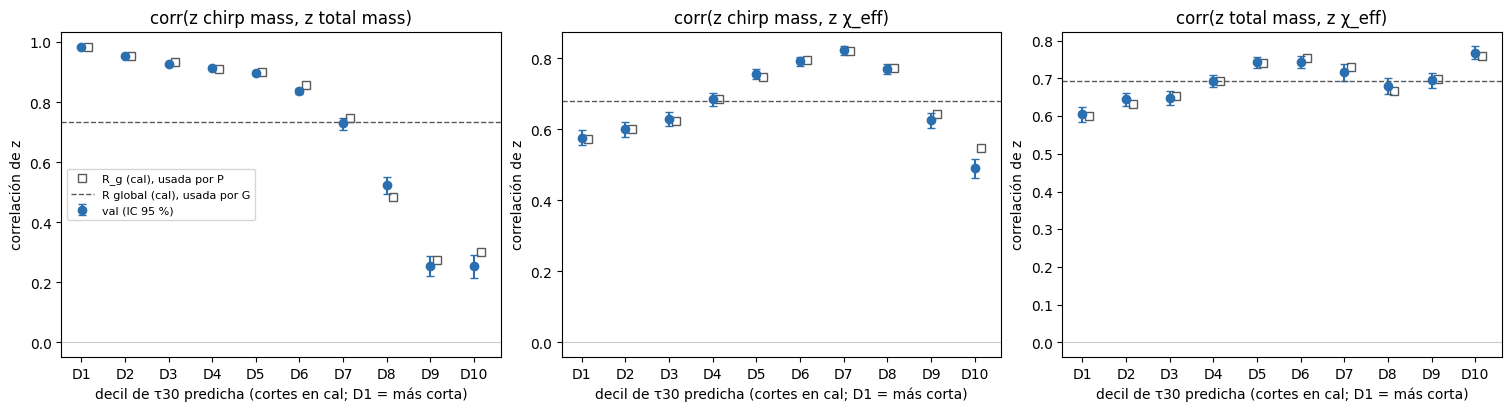

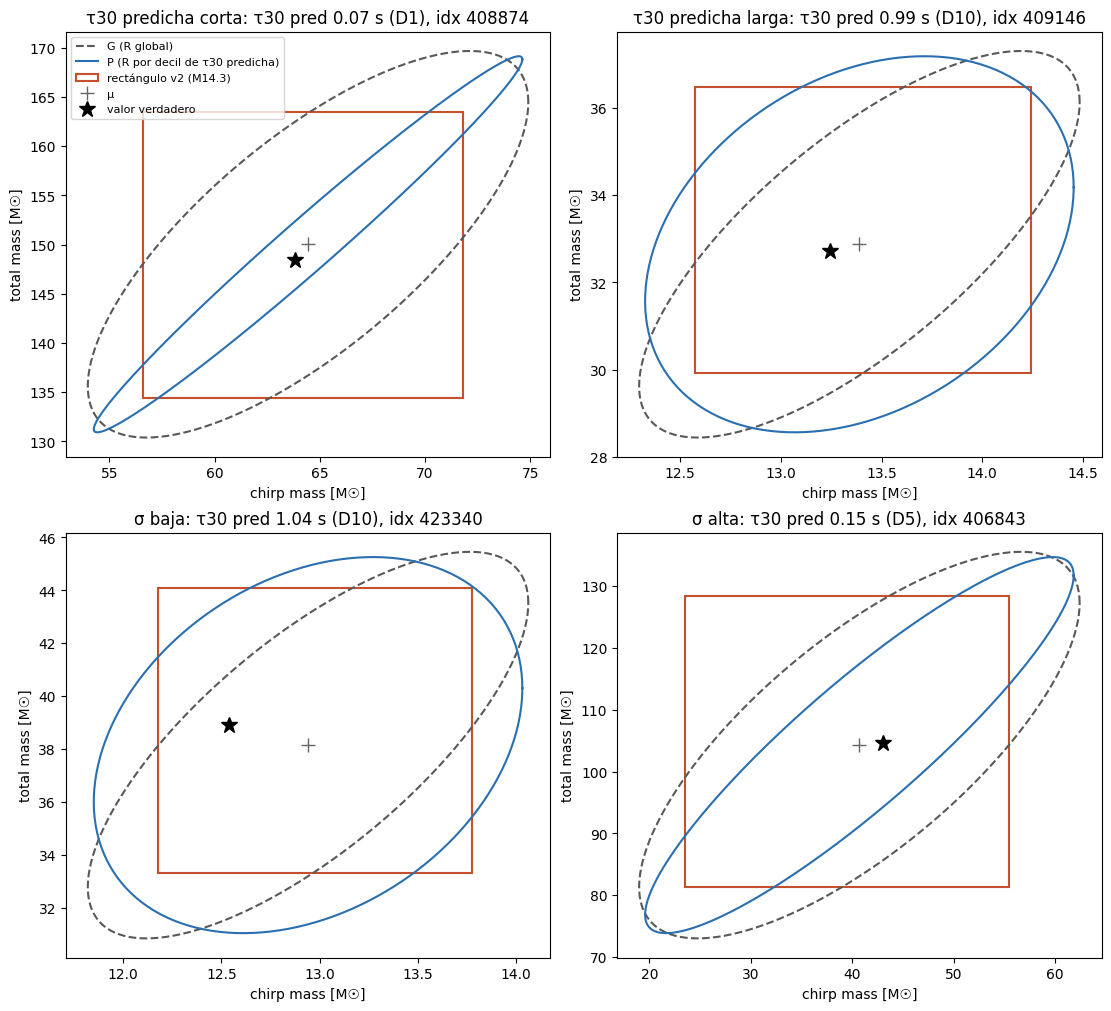

/data/vserrano/cbc_pe_data/results/M13_3/M14_4/figures/M14_4_val_z_correlation_by_tau_pred_decile_20261111T175706Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_4/figures/M14_4_val_z_correlation_by_tau_pred_decile_20261111T175706Z.pdf
/data/vserrano/cbc_pe_data/results/M13_3/M14_4/figures/M14_4_val_ellipses_2d_examples_20261111T175706Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_4/figures/M14_4_val_ellipses_2d_examples_20261111T175706Z.pdf


In [10]:
LNAME, UNITS, METH = CONFIG["labels"], CONFIG["units"], CONFIG["methods"]
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = []

def save_figure(fig, key):
    for ext in ("png", "pdf"):
        p = FIG_DIR / f"{CONFIG['fig_names'][key]}_{RUN_STAMP}.{ext}"
        with p.open("xb") as f:                      # never overwrites
            fig.savefig(f, format=ext, dpi=200, bbox_inches="tight")
        FIGURES.append(str(p))

# (a) Pairwise correlation of z vs predicted tau30 decile (val, 95 % bootstrap CI), with R_g of cal and R global.
dec_tab = CORR_VAL[CORR_VAL.grouping == "tau_pred_decile"]
x = np.arange(1, N_TAU_DECILES + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, (k, (i, j)), pair in zip(axes, enumerate(PAIRS), PAIR_NAMES):
    t = dec_tab[dec_tab.pair == pair]
    ax.errorbar(x, t["corr"], yerr=[t["corr"] - t.ci_lo, t.ci_hi - t["corr"]], fmt="o", capsize=3,
                color=CONFIG["val_color"], label="val (IC 95 %)")
    ax.plot(x + 0.15, R_DEC[:, i, j], "s", mfc="none", color=CONFIG["cal_color"], label="R_g (cal), usada por P")
    ax.axhline(R_GLOBAL[i, j], color=METH["G"]["color"], ls=METH["G"]["ls"], lw=1, label="R global (cal), usada por G")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set(title=f"corr(z {LNAME[LABELS[i]]}, z {LNAME[LABELS[j]]})", xticks=x,
           xticklabels=[f"D{v}" for v in x], xlabel="decil de τ30 predicha (cortes en cal; D1 = más corta)",
           ylabel="correlación de z")
axes[0].legend(fontsize=8)
save_figure(fig, "a")
plt.show()

# (b) Four representative val rows: 2D (chirp, total) ellipses of G and P, true value and v2 rectangle (physical units).
rep_vars = {"tau": TAU_PRED["val"], "sigma2d": np.log(SPLITS["val"]["sigma"][:, 0]) + np.log(SPLITS["val"]["sigma"][:, 1])}
REP_ROWS = {}
for name, (var, q) in CONFIG["representative"].items():
    v = rep_vars[var]
    REP_ROWS[name] = int(np.argmin(np.abs(v - np.quantile(v, q))))
check(len(set(REP_ROWS.values())) == len(REP_ROWS), "representative rows are distinct")
MU_VAL_PHYS = SPLITS["val"]["pred"] * y_std + y_mean
Y_VAL_PHYS = SPLITS["val"]["y"] * y_std + y_mean

def ellipse_xy(i, method, n_pts=300):
    sd = SPLITS["val"]["sigma"][i, :2] * y_std[:2]
    sigma_phys = corr_matrix(method, "val")[i][:2, :2] * np.outer(sd, sd)
    t = np.linspace(0, 2 * np.pi, n_pts)
    return MU_VAL_PHYS[i, :2, None] + np.sqrt(RADIUS[(method, "2D")]) * np.linalg.cholesky(sigma_phys) @ np.stack([np.cos(t), np.sin(t)])

titles = dict(tau_short="τ30 predicha corta", tau_long="τ30 predicha larga", sigma_low="σ baja", sigma_high="σ alta")
fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for ax, (name, i) in zip(axes.ravel(), REP_ROWS.items()):
    for m in METHODS:
        ex, ey = ellipse_xy(i, m)
        ax.plot(ex, ey, color=METH[m]["color"], ls=METH[m]["ls"], label=METH[m]["name"])
    lo, hi = V2_LOWER[i, :2], V2_UPPER[i, :2]
    ax.add_patch(plt.Rectangle(lo, *(hi - lo), fill=False, ec=CONFIG["v2"]["color"], lw=1.5, label=CONFIG["v2"]["name"]))
    ax.plot(*MU_VAL_PHYS[i, :2], "+", color="0.4", ms=10, label="μ")
    ax.plot(*Y_VAL_PHYS[i, :2], "*", color=CONFIG["truth_color"], ms=12, label="valor verdadero")
    ax.set(title=f"{titles.get(name, name)}: τ30 pred {TAU_PRED['val'][i]:.2f} s (D{DEC['val'][i] + 1}), idx {IDX_VAL[i]}",
           xlabel=f"{LNAME['chirp_mass']} [{UNITS['chirp_mass']}]", ylabel=f"{LNAME['total_mass']} [{UNITS['total_mass']}]")
    ax.autoscale_view()
axes[0, 0].legend(fontsize=8)
save_figure(fig, "b")
plt.show()
print("\n".join(FIGURES))

## 11. Resumen JSON (modo `'x'`)

In [11]:
summary = dict(
    experiment="M14.4", preregistration="docs/experiments/M14_4_residual_correlation.md (11-11-2026)",
    run_stamp_utc=RUN_STAMP, model_tag=TAG,
    inputs=dict(pred=INPUTS, split=str(SPLIT_PATH), label_stats=str(LABEL_STATS_PATH), g3_h5=str(G3_H5),
                m14_3_bundle=input_entry(M14_3_BUNDLE), m14_3_summary=str(M14_3_SUMMARY), m14_3_run=M14_3_RUN),
    npz_provenance=NPZ_PROVENANCE, reused_sources=reused_sources,
    gates=dict(checks=CHECKS, rmse_val=RMSE_VAL, rmse_val_expected=RMSE_VAL_EXPECTED),
    groups=dict(tau_pred_edges_cal_s=TAU_EDGES_CAL, tau_groups=TAU_GROUPS, sigma_chirp_cuts_cal_std=SIG_CHIRP_CUTS_CAL,
                snr_cuts_val=SNR_CUTS, snr_source=f"G3 nominal {SNR_KEY} of {G3_H5.name}, aligned by idx_val (truth)"),
    design=dict(level=LEVEL, k_rank=K_RANK, n_cal=n_cal, n_val=n_val, dims={k: list(v) for k, v in DIMS.items()},
                R_global_cal=R_GLOBAL, R_decile_cal=R_DEC, radius={f"{m}/{dim}": r for (m, dim), r in RADIUS.items()},
                volume_note="physical units, c_d sqrt(det Sigma_phys) r^(d/2)"),
    validity=dict(band_level=VALID_BAND_LEVEL, table=records(VALIDITY), valid=VALID),
    gain=dict(n_boot=N_BOOT, seed=SEED_BOOT, ci_level=CI_LEVEL,
              note="paired row bootstrap of val, one draw per replicate for 3D and 2D; radii and R fixed (no cal noise)",
              table=records(GAIN)),
    decision=DECISION,
    descriptive_correlations=dict(n_boot=N_BOOT_DESC, seed=SEED_DESC, note="seed and B not fixed by the doc",
                                  val=records(CORR_VAL), cal_R_decile=records(R_CAL_TABLE)),
    descriptive_v2=dict(note="v1 bundle of M14.3 run, v2 refitted on cal with M14.3 fit_v2; reproduced M14.3 offsets and SNR table",
                        simultaneous=records(SIMULTANEOUS), volumes=records(VOLUMES)),
    figures=FIGURES, representative_rows={k: dict(row=i, idx=int(IDX_VAL[i])) for k, i in REP_ROWS.items()},
)
SUMMARY_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
SUMMARY_PATH = OUT_ROOT / f"M14_4_summary_{SUMMARY_STAMP}.json"   # new file each time this cell runs ('x' mode)
summary["summary_stamp_utc"] = SUMMARY_STAMP
OUT_ROOT.mkdir(parents=True, exist_ok=True)
with SUMMARY_PATH.open("x", encoding="utf-8") as f:
    json.dump(to_json(summary), f, indent=2, ensure_ascii=False)
print("Summary:", SUMMARY_PATH)
print("Decisión:", DECISION)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M14_4/M14_4_summary_20261111T175754Z.json
Decisión: {'valid_G_3D': True, 'valid_P_3D': True, 'ci_hi_delta_3d_pct': -34.22483374319843, 'threshold_pct': -10.0, 'full_covariance_head_justified': True}


## Lectura (11-11-2026)

**Veredicto pre-registrado:** G y P válidas en 3D; Δ volumen 3D = −34,5 % [−34,7; −34,2] ≤ −10 % → **se justifica la cabeza heterocedástica con covarianza completa.**

### Verificado (val G3T, 40 000 filas; R y radios en cal; M14.1, una semilla)
- **Gates:** 50 comprobaciones; mismos npz que M14.3; RMSE de val reproducido.
- **Correlación de z por decil de τ30 predicha** (cal ≈ val en todos los deciles):
  - 𝓜–M_tot de 0,985 (D1, señales cortas) a 0,25 (D9–D10, largas);
  - M_tot–χ_eff de 0,60 a 0,77;
  - 𝓜–χ_eff con máximo ~0,82 en D7.
  - Por terciles de SNR apenas cambia (𝓜–M_tot 0,75 / 0,72 / 0,70).
- **Cobertura conjunta (val), global y por D1–D3 / D4–D7 / D8–D10:**
  - G 3D: 0,9006; 0,922 / 0,936 / 0,835.
  - P 3D: 0,9007; 0,910 / 0,898 / 0,896.
  - G 2D (𝓜, M_tot): 0,9000 (0,954 / 0,936 / 0,802); P 2D: 0,9030 (0,911 / 0,898 / 0,903).
  - P 2D supera la banda binomial por 0,0001 (sobrecobertura; banda sin ruido de cal; no entra en la decisión).
- **Volumen (media geométrica):** P frente a G −34,5 % (3D) y −29,9 % (2D).
- **Rectángulos v2 de M14.3:** cobertura simultánea 0,816 (3D) y 0,859 (2D), uniforme en grupos de τ y de SNR. Volumen 114,6 frente a 71,5 del elipsoide P (con cobertura 0,90).

### Interpretación
- **(Verificado):** la orientación de la degeneración cambia fuertemente con la duración de la señal y no con el SNR. Una R global da regiones válidas solo en promedio (0,80–0,84 en señales largas). Una R por régimen deja la cobertura casi plana y reduce el volumen un tercio.
- **(Hipótesis, coherente con la física de CBC):** en señales cortas el merger-ringdown fija M_tot y 𝓜 hereda su error (correlación ≈ 1); en señales largas la fase del inspiral fija 𝓜 de forma independiente y el error de M_tot viene del cociente de masas, degenerado con χ_eff.
- **(Verificado):** tres intervalos al 90 % por separado cubren el sistema completo solo el 82 % de las veces. Para el sistema conjunto, la región adecuada es el elipsoide.

### Limitaciones y no se puede concluir
- Cal se usa para estimar R_g y para calibrar el radio. El efecto es despreciable aquí (cobertura de val 0,9007), pero el método final debe estimar R fuera de cal.
- La ganancia adicional de una Σ(x) aprendida sobre P (R por tramos) no se conoce.
- Una semilla; simulación; IC sin ruido de cal; sin datos reales.